# Gemini 2027A targets

The transients in `gemini_2027A.txt`, loaded the way `Source_Analysis/store_src_plots.py` loads them: matched on sky into the filter run's candidate tables, then built with `Sources.from_table` using the same light-curve catalogs, local store and ZTF data directory.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord

REPO = os.path.abspath('..')
sys.path.insert(0, REPO)
sys.path.insert(0, os.path.join(REPO, 'Source_Analysis'))

import store_src_plots as ssp   # its plot style, local store and matching helper
from Extracting.utils import get_data_path, load_ecsv
from Sources import Sources

CasJobs will use the credentials from mast_dino_login.txt
In preparation for Gaia DR4, the Gaia archive is in evolution. Unfortunately, it may be unstable at times and particular types of queries may time out. Please consider registering for a user account (https://www.cosmos.esa.int/web/gaia-users/register). For questions or advice, please contact the Gaia helpdesk (https://www.cosmos.esa.int/web/gaia/gaia-helpdesk).


## Load the sources

In [2]:
targets = np.loadtxt(os.path.join(REPO, 'gemini_2027A.txt'), delimiter=',')
wanted = SkyCoord(targets[:, 0], targets[:, 1], unit='deg')
print(f'{len(wanted)} targets')

data = get_data_path()
store = ssp.make_store()
LC_CATALOGS = ['ztf', 'wise', 'neowise', 'ptf', 'sdss', 'panstarrs', 'gaia', 'custom']

# Each target lives in one tier's table; build its Source from that row, and
# keep the file's order so srcs[i] is line i of gemini_2027A.txt.
srcs = [None] * len(wanted)
tier_of = [None] * len(wanted)
for tier in ['0', '1', '1_wide_association']:
    path = os.path.join(data, f'{ssp.FILTER_RESULTS_DIRNAME}/combined/{tier}.hdf5')
    todo = np.array([s is None for s in srcs])
    if not todo.any():
        break
    table, ok = ssp.restrict_to_exciting(load_ecsv(path), wanted[todo])
    if len(table) == 0:
        continue
    built = Sources.from_table(
        table,
        lc_catalogs=LC_CATALOGS,
        filtering_dirpath=os.path.dirname(os.path.dirname(path)),
        ztf_data_dir=os.path.join(data, 'ztf_data'),
        store=store,
    )
    for i, src in zip(np.where(todo)[0][ok], built):
        srcs[i], tier_of[i] = src, tier

missing = [f'{c.ra.deg:.5f}, {c.dec.deg:.5f}' for c, s in zip(wanted, srcs) if s is None]
print('tiers:', {t: tier_of.count(t) for t in set(tier_of)})
print('not found in any candidate table:', missing or 'none')

24 targets
LOCAL_DB: serving from release 1 (197933 sources, built from filter_results_9_21_2026_full_catalog_fixed_pm)
  cutouts and spectra still use the live path.
  matched 5 into the candidate table
  matched 19 into the candidate table
tiers: {'0': 5, '1': 19}
not found in any candidate table: none


## ZTF r-band light curves

One panel per target, in file order, on a shared time axis. Magnitudes are the ZTF data-release light curve (`r_mag`) as `Light_Curve` serves it.

Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local stor

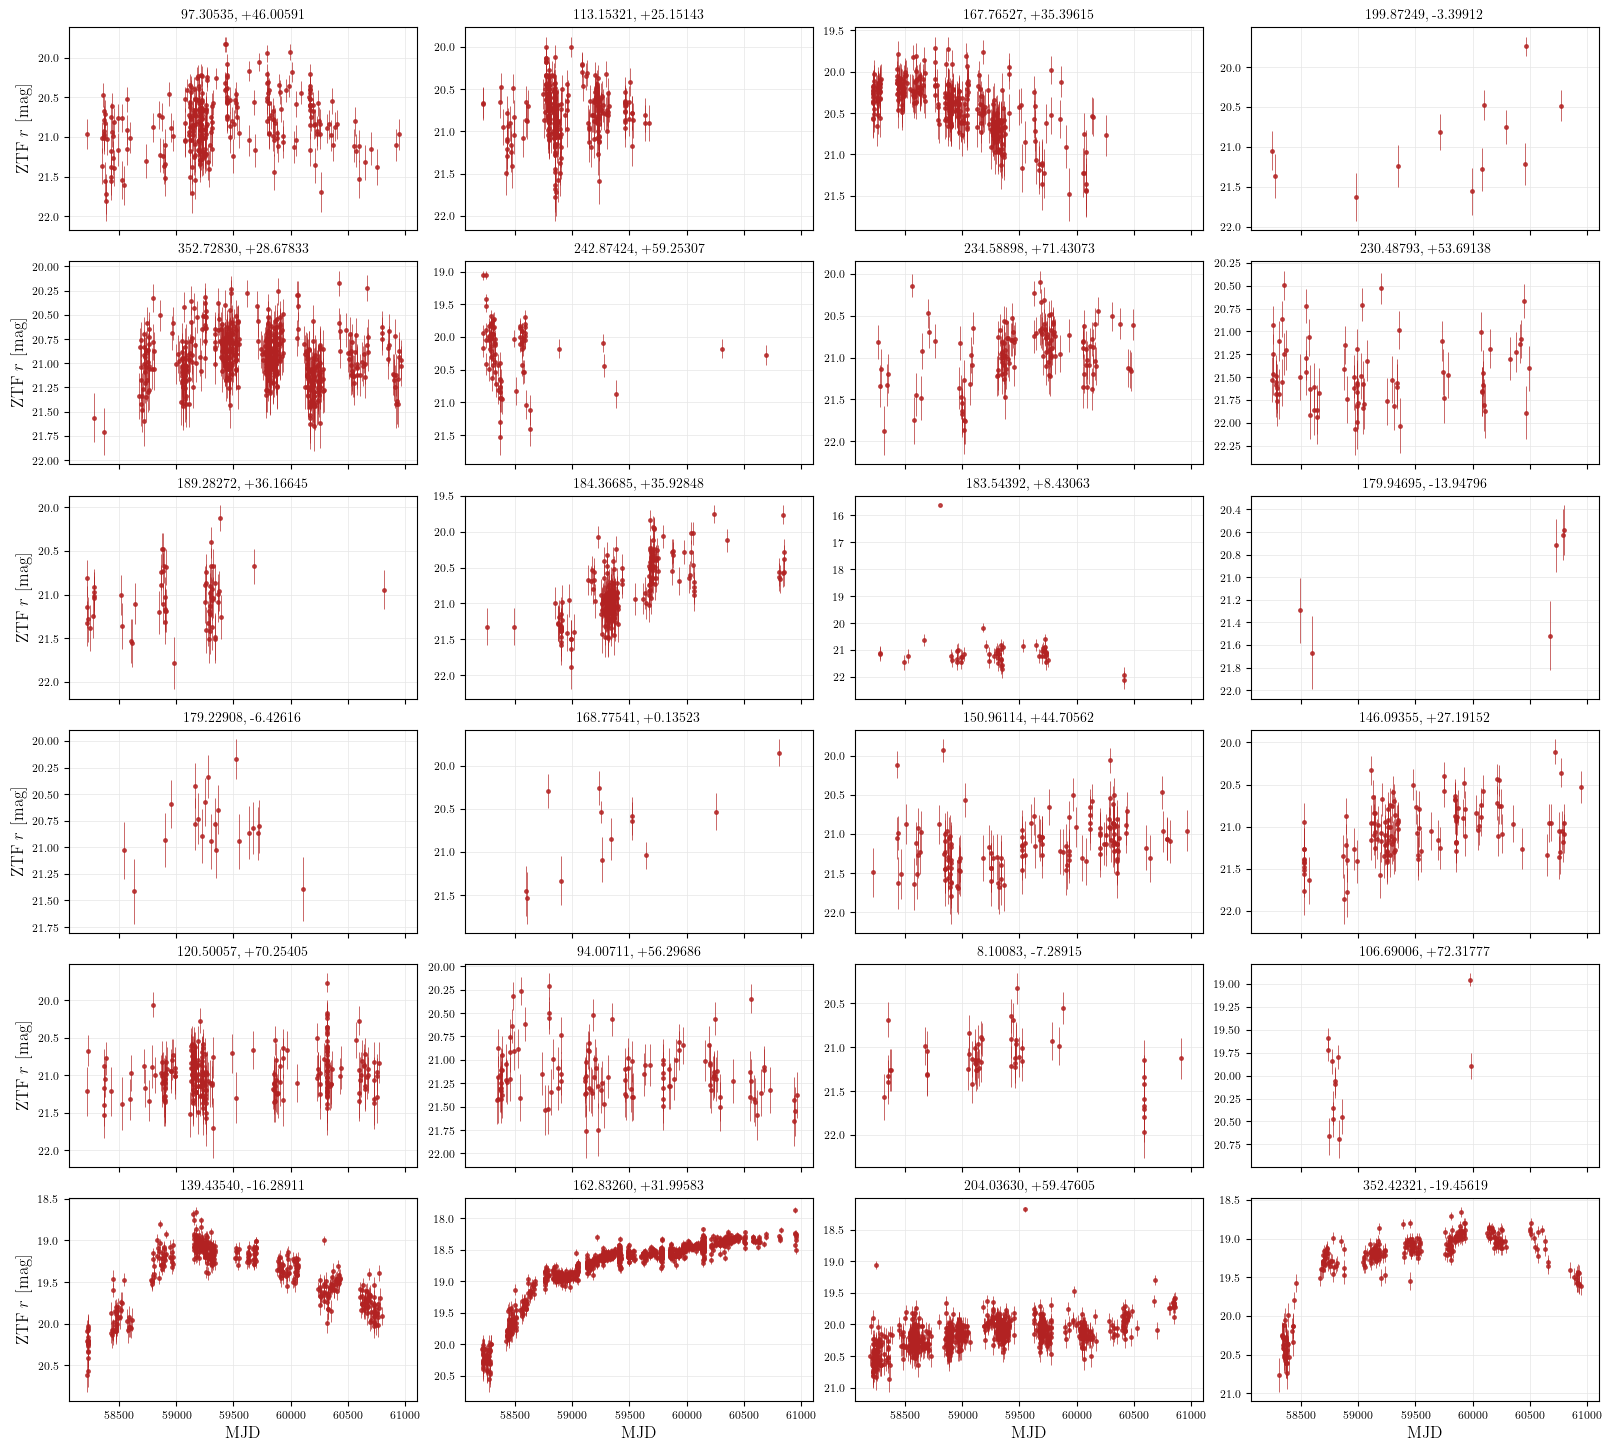

In [3]:
found = [(i, s) for i, s in enumerate(srcs) if s is not None]
ncol = 4
nrow = int(np.ceil(len(found) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.4 * nrow),
                         sharex=True, constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, (i, src) in zip(axes, found):
    lc = src.light_curve.lc
    title = f'{src.ra:.5f}, {src.dec:+.5f}'
    if 'r_mag' not in lc.colnames or np.all(np.ma.getmaskarray(lc['r_mag'])):
        ax.text(0.5, 0.5, 'no ZTF r data', transform=ax.transAxes,
                ha='center', va='center', color='0.4')
    else:
        good = ~np.ma.getmaskarray(lc['r_mag'])
        ax.errorbar(np.asarray(lc['mjd'])[good], np.ma.filled(lc['r_mag'], np.nan)[good],
                    yerr=np.ma.filled(lc['r_magerr'], np.nan)[good],
                    fmt='o', ms=2.5, color='firebrick', ecolor='firebrick',
                    elinewidth=0.6, alpha=0.8)
        ax.invert_yaxis()
    ax.set_title(title, fontsize=10)
    ax.grid(color='0.9', lw=0.5)
    ax.tick_params(labelsize=8)

for ax in axes[len(found):]:
    ax.set_visible(False)
for ax in axes[(nrow - 1) * ncol:]:
    ax.set_xlabel('MJD')
for ax in axes[::ncol]:
    ax.set_ylabel('ZTF $r$ [mag]')

fig.savefig('gemini_2027A_ztf_r.pdf', bbox_inches='tight')
plt.show()

## ZTF and Pan-STARRS g, r, i, one panel per target

Each panel is one target, in file order: its ZTF data-release epochs and Pan-STARRS single epochs in g, r and i, with the analysis pages' colours (band) and markers (survey). The short bars on each magnitude axis mark the Pan-STARRS 5σ limit per band (`ssp.PSTARR_UPPER_LIM`: g 23.3, r 23.2, i 23.1).

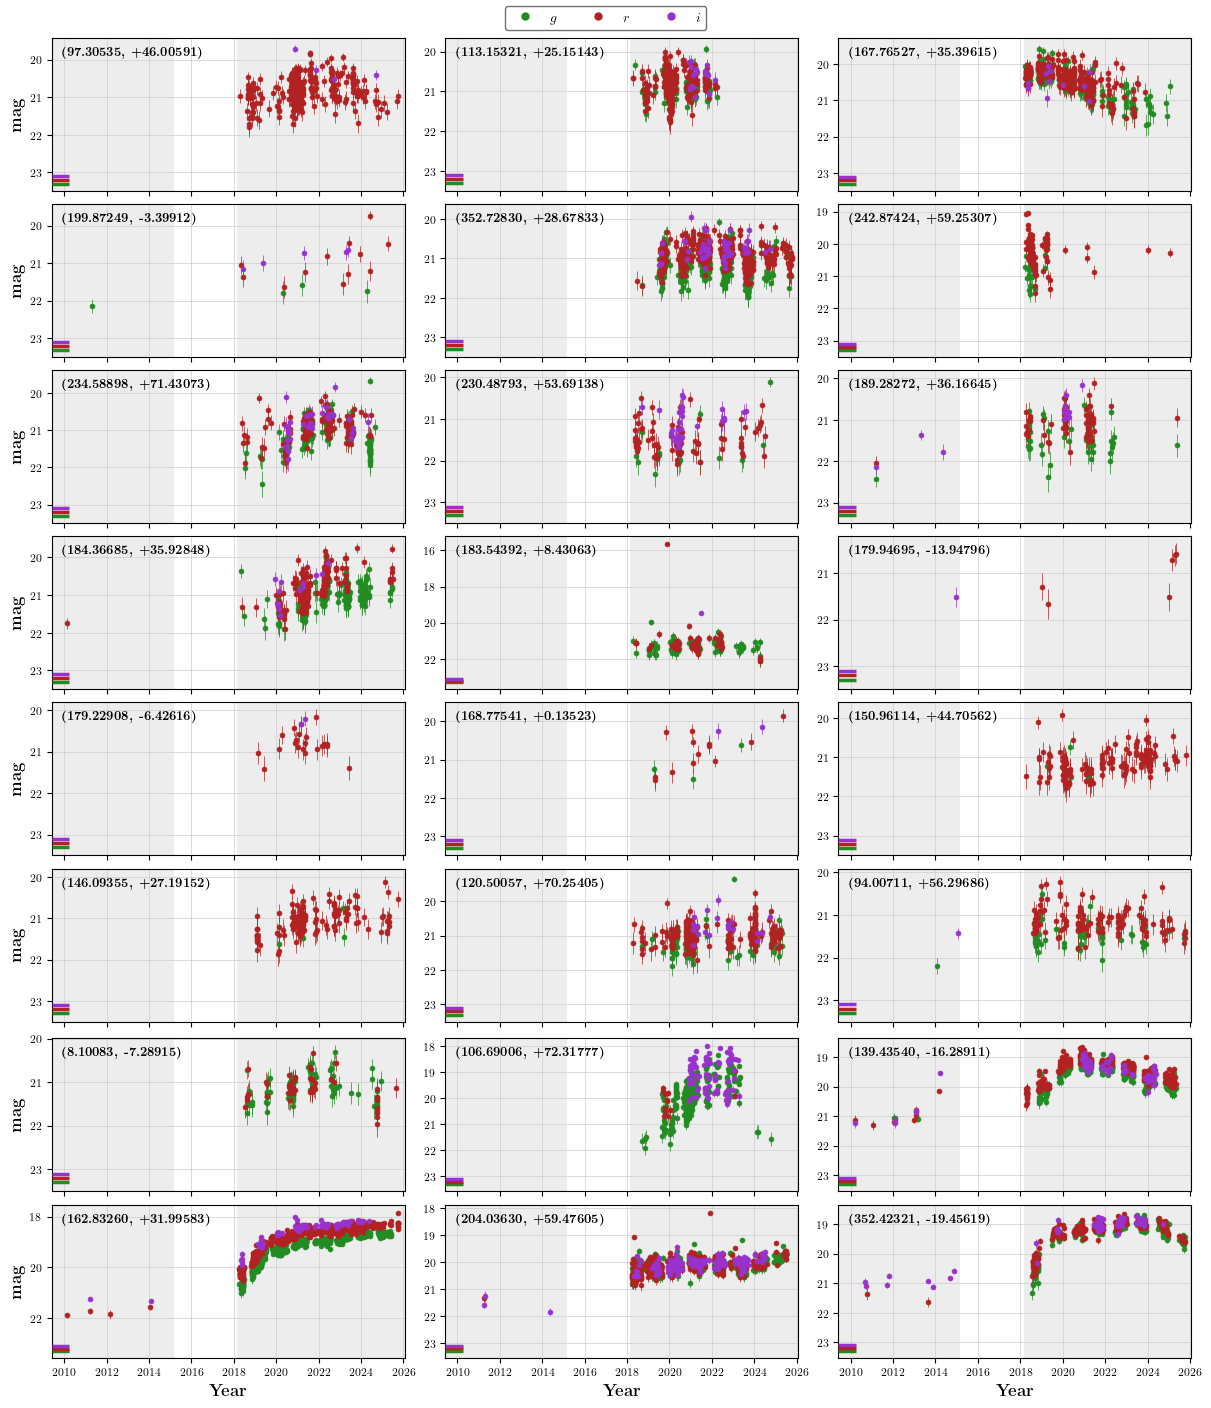

In [24]:
from astropy.time import Time
from matplotlib.lines import Line2D
from matplotlib.transforms import blended_transform_factory
from Light_Curve import LC_COLOR_INFO

BANDS = ['g', 'r', 'i']
SURVEYS = {'ztf': '{b}_mag', 'panstarrs': 'pstarr_{b}_mag'}   # Light_Curve column names
# When each survey's data were taken, in decimal years. Pan-STARRS: the span of the
# 3pi data in DR2, "2010-2014, with some observations in 2009 and 2015" (Flewelling
# et al. 2020); the local light curves run 2009-06-03 to 2015-02-25. ZTF: DR24, which
# covers March 2018 - 22 Oct 2025 (ztf.caltech.edu public releases); the local
# light curves run 2018-03-20 to 2025-10-22.
EPOCHS = {'panstarrs': (Time('2009-06-01').decimalyear, Time('2015-03-01').decimalyear),
          'ztf': (Time('2018-03-01').decimalyear, Time('2025-10-23').decimalyear + 0.25)}
EPOCH_COLOR = '0.93'

ncol, nrow = 3, 8
assert ncol * nrow >= len(found)
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 1.75 * nrow),
                         sharex=True, constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, (i, src) in zip(axes, found):
    lc = src.light_curve.lc
    mjd = np.ma.filled(np.ma.asarray(lc['mjd'], dtype=float), np.nan)
    for survey, pattern in SURVEYS.items():
        for band in BANDS:
            mag_col = pattern.format(b=band)
            err_col = mag_col.replace('_mag', '_magerr')
            if mag_col not in lc.colnames:
                continue
            good = ~np.ma.getmaskarray(lc[mag_col]) & np.isfinite(mjd)   # Time() rejects NaN
            if not good.any():
                continue
            ax.errorbar(Time(mjd[good], format='mjd').decimalyear,
                        np.ma.filled(lc[mag_col], np.nan)[good],
                        yerr=np.ma.filled(lc[err_col], np.nan)[good] if err_col in lc.colnames else None,
                        fmt='o', ms=3.5, mew=0.5,
                        elinewidth=0.5, capsize=0, color=LC_COLOR_INFO[band])

    for survey, (start, end) in EPOCHS.items():
        ax.axvspan(start, end, color=EPOCH_COLOR, zorder=-1, lw=0)   # below the grid
    ax.invert_yaxis()
    # Short bars on the magnitude axis at the Pan-STARRS limit, one per band.
    on_axis = blended_transform_factory(ax.transAxes, ax.transData)
    for band in BANDS:
        lim = ssp.PSTARR_UPPER_LIM[band]
        ax.plot([0, 0.05], [lim, lim], transform=on_axis, color=LC_COLOR_INFO[band],
                lw=2.5, solid_capstyle='butt', clip_on=False, zorder=5)
    lo, hi = ax.get_ylim()                       # inverted: lo is the faint end
    ax.set_ylim(max(lo, max(ssp.PSTARR_UPPER_LIM.values()) + 0.2), hi)   # keep the bars in view

    ax.text(0.03, 0.95, rf'\textbf{{({src.ra:.5f}, {src.dec:+.5f})}}', transform=ax.transAxes,
            ha='left', va='top', fontsize=9)
    ax.set_axisbelow(True)      # grid (zorder 0.5) over the survey boxes, under the data
    ax.grid(color='0.8', lw=0.5)
    ax.tick_params(labelsize=8)

for ax in axes[len(found):]:
    ax.set_visible(False)
for ax in axes[(nrow - 1) * ncol:]:
    ax.set_xlabel(r'\textbf{Year}')
for ax in axes[::ncol]:
    ax.set_ylabel(r'\textbf{mag}')

handles = [Line2D([], [], ls='none', marker='o', ms=5, color=LC_COLOR_INFO[b], label=f'${b}$') for b in BANDS]
axes[0].set_xlim(EPOCHS['panstarrs'][0], EPOCHS['ztf'][1])   # shared x: sets every panel
fig.legend(handles=handles, loc='outside upper center', ncol=len(BANDS), fontsize=10, edgecolor='0.3')

plt.savefig('/Users/adamboesky/Research/long_transients/Figures/lightcurves_gemini_2027A.pdf')
plt.show()

## Most recent ZTF detection

For each target, the latest epoch in its ZTF data-release light curve (`g_mag`, `r_mag`, `i_mag`), in any band. DR24 ends on 2025-10-22, so no date here is later than that.

In [51]:
import pandas as pd
import astropy.units as u
from astropy.time import Time

rows = []
for i, src in found:
    lc = src.light_curve.lc
    mjd = np.ma.filled(np.ma.asarray(lc['mjd'], dtype=float), np.nan)
    best = None                                   # (mjd, mag, err, band) of the latest epoch
    for band in ['g', 'r', 'i']:
        col = f'{band}_mag'
        if col not in lc.colnames:
            continue
        good = ~np.ma.getmaskarray(lc[col]) & np.isfinite(mjd)
        if not good.any():
            continue
        k = np.flatnonzero(good)[np.argmax(mjd[good])]
        if best is None or mjd[k] > best[0]:
            err = np.ma.filled(lc[f'{band}_magerr'], np.nan)[k] if f'{band}_magerr' in lc.colnames else np.nan
            best = (mjd[k], float(np.ma.filled(lc[col], np.nan)[k]), float(err), band)
    coord = SkyCoord(src.ra, src.dec, unit='deg')
    rows.append({
        'RA': coord.ra.to_string(unit=u.hourangle, sep=':', precision=2, pad=True),
        'Dec': coord.dec.to_string(unit=u.deg, sep=':', precision=1, pad=True, alwayssign=True),
        'mag': f'{best[1]:.2f} ± {best[2]:.2f}' if best else '',
        'band': best[3] if best else '',
        'date': Time(best[0], format='mjd').iso[:10] if best else '',
        'mag_value': best[1] if best else np.nan,   # numeric copy, for sorting only
    })

# Brightest first; targets with no ZTF detection last.
latest = (pd.DataFrame(rows)
          .sort_values('mag_value', na_position='last', kind='stable')
          .reset_index(drop=True))
# As a LaTeX table: plain \hline rules, so it needs no extra packages.
def tex_cell(value):
    if not value:
        return '---'
    return value.replace(' ± ', r' $\pm$ ').replace('-', '$-$', 1) if value[0] == '-' else value.replace(' ± ', r' $\pm$ ')

lines = [r'\begin{table}', r'\centering',
         r'\caption{Most recent ZTF detection of each target (ZTF DR24).}',
         r'\begin{tabular}{llcll}',
         r'RA (J2000) & Dec (J2000) & Magnitude & Band & Date \\', r'\hline']
for r in latest.itertuples(index=False):
    band = f'${r.band}$' if r.band else '---'
    lines.append(' & '.join([tex_cell(r.RA), tex_cell(r.Dec), tex_cell(r.mag), band, tex_cell(r.date)]) + r' \\')
lines += [r'\end{tabular}', r'\end{table}']
print('\n'.join(lines))

\begin{table}
\centering
\caption{Most recent ZTF detection of each target (ZTF DR24).}
\begin{tabular}{llcll}
RA (J2000) & Dec (J2000) & Magnitude & Band & Date \\
\hline
10:51:19.82 & +31:59:45.0 & 18.27 $\pm$ 0.05 & $r$ & 2025-10-06 \\
23:29:41.57 & $-$19:27:22.3 & 19.56 $\pm$ 0.10 & $g$ & 2025-10-03 \\
13:36:08.71 & +59:28:33.8 & 19.75 $\pm$ 0.11 & $g$ & 2025-07-03 \\
11:15:06.10 & +00:08:06.8 & 19.85 $\pm$ 0.16 & $r$ & 2025-05-16 \\
09:17:44.50 & $-$16:17:20.8 & 19.91 $\pm$ 0.11 & $r$ & 2025-04-30 \\
15:21:57.10 & +53:41:29.0 & 20.12 $\pm$ 0.12 & $g$ & 2024-09-22 \\
16:11:29.82 & +59:15:11.1 & 20.27 $\pm$ 0.15 & $r$ & 2025-01-18 \\
13:19:29.40 & $-$03:23:56.8 & 20.48 $\pm$ 0.19 & $r$ & 2025-04-10 \\
09:44:22.45 & +27:11:29.5 & 20.53 $\pm$ 0.19 & $r$ & 2025-10-02 \\
12:17:28.05 & +35:55:42.5 & 20.57 $\pm$ 0.19 & $r$ & 2025-06-27 \\
11:59:47.27 & $-$13:56:52.7 & 20.58 $\pm$ 0.22 & $r$ & 2025-05-01 \\
11:11:03.66 & +35:23:46.1 & 20.62 $\pm$ 0.21 & $g$ & 2025-01-23 \\
07:32:36.77 & +2

## Four highlighted targets

The same light-curve panels as above for four targets, as a 2×2 grid. Uses `BANDS`, `SURVEYS`, `EPOCHS` and the imports from the g, r, i cell, so run that first.

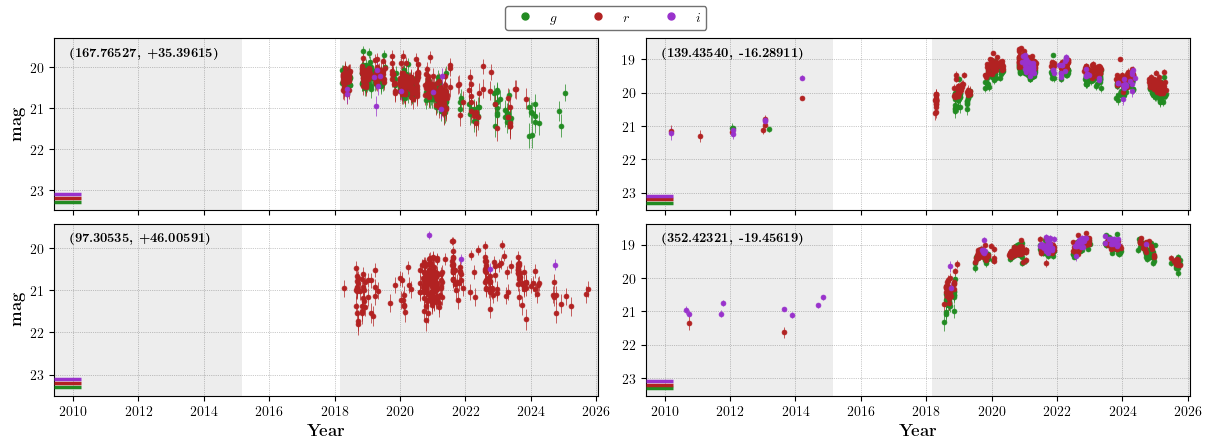

In [48]:
# Targets by RA, in the order they are drawn (left to right, top to bottom). Matched on RA
# rounded to as many decimals as given, since these came from the 4-decimal labels.
RA_PREFIXES = ['167.7653', '139.4354', '97.305', '352.4232']
picked = []
for prefix in RA_PREFIXES:
    ndec = len(prefix.split('.')[1])
    hits = [src for _, src in found if f'{src.ra:.{ndec}f}' == prefix]
    assert len(hits) == 1, f'{len(hits)} targets have an RA of {prefix}'
    picked.append(hits[0])

ncol, nrow = 2, 2
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 2 * nrow + 0.4),
                         sharex=True, constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, src in zip(axes, picked):
    lc = src.light_curve.lc
    mjd = np.ma.filled(np.ma.asarray(lc['mjd'], dtype=float), np.nan)
    for survey, pattern in SURVEYS.items():
        for band in BANDS:
            mag_col = pattern.format(b=band)
            err_col = mag_col.replace('_mag', '_magerr')
            if mag_col not in lc.colnames:
                continue
            good = ~np.ma.getmaskarray(lc[mag_col]) & np.isfinite(mjd)   # Time() rejects NaN
            if not good.any():
                continue
            ax.errorbar(Time(mjd[good], format='mjd').decimalyear,
                        np.ma.filled(lc[mag_col], np.nan)[good],
                        yerr=np.ma.filled(lc[err_col], np.nan)[good] if err_col in lc.colnames else None,
                        fmt='o', ms=3.5, mew=0.5,
                        elinewidth=0.5, capsize=0, color=LC_COLOR_INFO[band])

    for survey, (start, end) in EPOCHS.items():
        ax.axvspan(start, end, color=EPOCH_COLOR, zorder=-1, lw=0)   # below the grid
    ax.invert_yaxis()
    # Short bars on the magnitude axis at the Pan-STARRS limit, one per band.
    on_axis = blended_transform_factory(ax.transAxes, ax.transData)
    for band in BANDS:
        lim = ssp.PSTARR_UPPER_LIM[band]
        ax.plot([0, 0.05], [lim, lim], transform=on_axis, color=LC_COLOR_INFO[band],
                lw=2.5, solid_capstyle='butt', clip_on=False, zorder=5)
    lo, hi = ax.get_ylim()                       # inverted: lo is the faint end
    ax.set_ylim(max(lo, max(ssp.PSTARR_UPPER_LIM.values()) + 0.2), hi)   # keep the bars in view

    ax.text(0.03, 0.95, rf'\textbf{{({src.ra:.5f}, {src.dec:+.5f})}}', transform=ax.transAxes,
            ha='left', va='top', fontsize=9)
    ax.set_axisbelow(True)      # grid (zorder 0.5) over the survey boxes, under the data
    ax.grid(color='k', lw=0.5, alpha=0.4, ls=':')
    ax.tick_params(labelsize=10)

for ax in axes[(nrow - 1) * ncol:]:
    ax.set_xlabel(r'\textbf{Year}')
for ax in axes[::ncol]:
    ax.set_ylabel(r'\textbf{mag}')

handles = [Line2D([], [], ls='none', marker='o', ms=5, color=LC_COLOR_INFO[b], label=f'${b}$') for b in BANDS]
axes[0].set_xlim(EPOCHS['panstarrs'][0], EPOCHS['ztf'][1])   # shared x: sets every panel
fig.legend(handles=handles, loc='outside upper center', ncol=len(BANDS), fontsize=10, edgecolor='0.3')

plt.savefig('/Users/adamboesky/Research/long_transients/Figures/lightcurves_gemini_2027A_highlight.pdf')
plt.show()

## Four highlighted targets, with cutouts

Each target as a block: its Pan-STARRS and ZTF $r$-band cutouts (drawn by `Postage_Stamp.plot_cutout`, so with the same reticle and 10" scale bar as the analysis pages, re-stretched with zscale in inverted greyscale, trimmed to the same 45" window centred on the target in both surveys, with a 10" scale bar sized from each image's WCS, and labelled with the catalog PSF magnitude where there is one), above the light-curve panel from the cell before. Uses the settings from the g, r, i cell, so run that first. The cutouts are downloaded on first use.

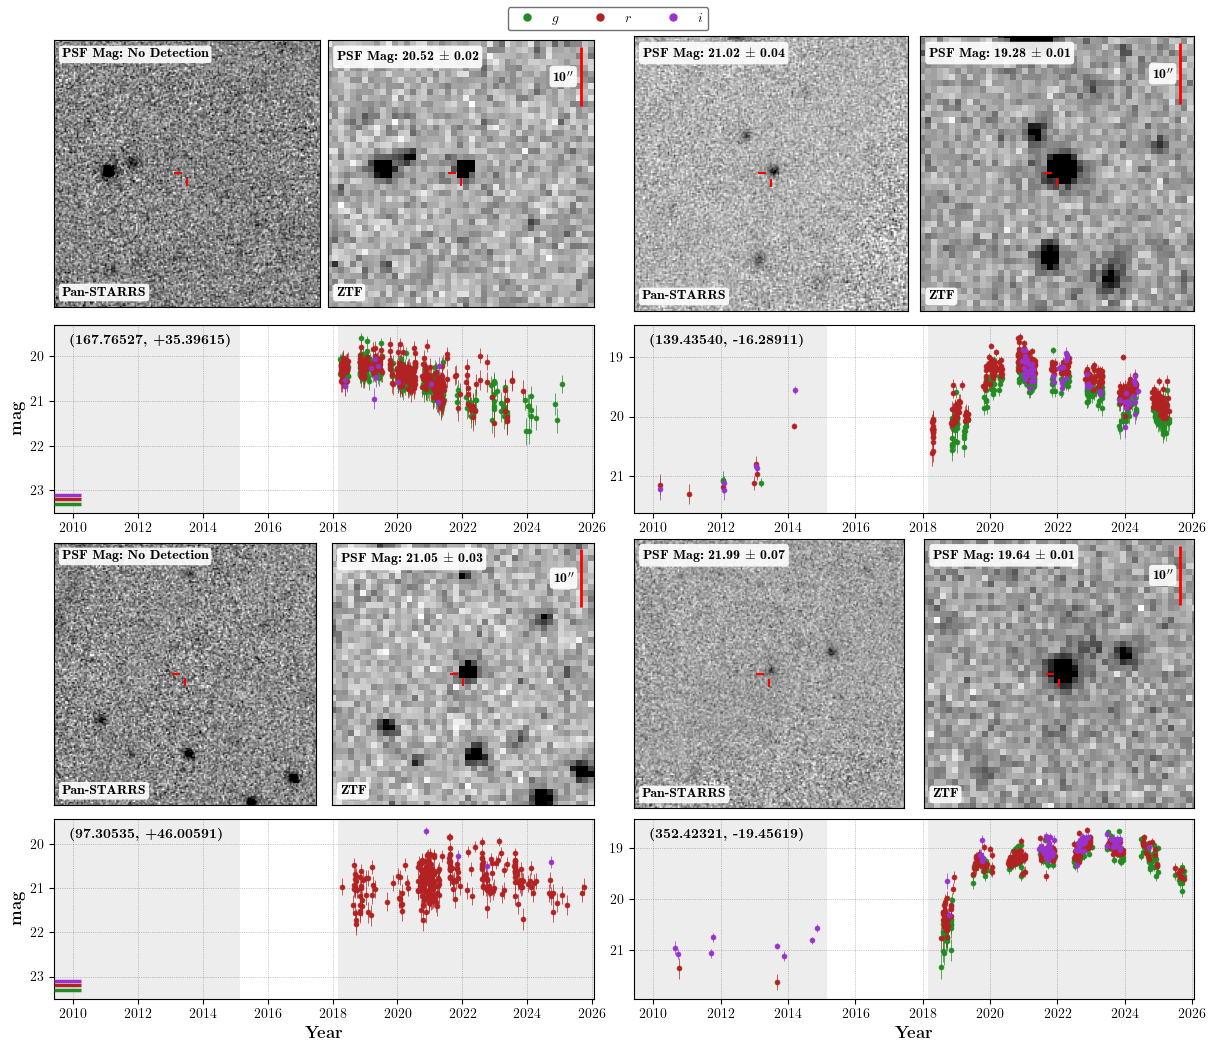

In [52]:
from astropy.visualization import ImageNormalize, LinearStretch, ZScaleInterval
from astropy.wcs.utils import proj_plane_pixel_scales
from Sources import format_magerr

CUTOUT_BAND = 'r'
CUTOUT_CMAP = 'gray_r'   # inverted greyscale: sources dark on a light sky
# Every stamp shows the same window on the sky, centred on the target. The stamps are requested
# at 50", but ZTF's crop truncates to whole pixels, comes back 49-50" (sometimes not square) and
# leaves the target up to ~1.3 px off-centre, so both surveys are trimmed to a common 45" that
# fits inside every crop.
CUTOUT_HALF_ARCSEC = 22.5
SCALE_BAR_ARCSEC = 10.0
# Annotations over the stamps: black on a white box, so they read on any part of the image.
LABEL_BOX = dict(facecolor='white', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.9)


def boxed_label(ax, x, y, text, **kwargs):
    """Black, bold text on LABEL_BOX. Drawn without usetex: with it, matplotlib sizes the box
    from the height and depth LaTeX reports, which do not match where the glyphs land, so the
    text sits 1-2.5 px high in its box. Plain text in cmb10 (Computer Modern Bold, bundled
    with matplotlib) centres properly and still matches the figure's LaTeX lettering."""
    return ax.text(x, y, text, usetex=False, fontfamily='cmb10', math_fontfamily='cm',
                   color='black', bbox=LABEL_BOX, **kwargs)
# Targets by RA, in the order they are drawn (left to right, top to bottom). Matched on RA
# rounded to as many decimals as given, since these came from the 4-decimal labels.
RA_PREFIXES = ['167.7653', '139.4354', '97.305', '352.4232']
picked = []
for prefix in RA_PREFIXES:
    ndec = len(prefix.split('.')[1])
    hits = [src for _, src in found if f'{src.ra:.{ndec}f}' == prefix]
    assert len(hits) == 1, f'{len(hits)} targets have an RA of {prefix}'
    picked.append(hits[0])


def draw_cutout(ax, src, survey, band=CUTOUT_BAND):
    """One survey's cutout, drawn by Postage_Stamp.plot_cutout (reticle + 10" scale bar),
    with its catalog PSF magnitude on top, or 'No Detection' where there is none."""
    stamp = src.postage_stamps['PSTARR' if survey == 'Pan-STARRS' else 'ZTF']
    try:
        stamp.plot_cutout(band=band, ax=ax, cmap=CUTOUT_CMAP)
        has_image = stamp.images[band] is not None
        if has_image:
            # plot_cutout's log stretch clips at the 99.5th percentile, which turns an empty
            # field's sky near-black in an inverted map; zscale keeps the sky an even light grey.
            ax.images[0].set_norm(ImageNormalize(stamp.images[band], interval=ZScaleInterval(),
                                                 stretch=LinearStretch()))
            # Same angular window in both surveys, using each image's own WCS pixel scale.
            # The -1 matches where plot_cutout draws the reticle.
            x, y = (float(v) - 1 for v in stamp.ra_dec_to_pix(src.ra, src.dec, band))
            half = CUTOUT_HALF_ARCSEC / (proj_plane_pixel_scales(stamp.WCSs[band].celestial).mean() * 3600)
            h, w = stamp.images[band].shape
            if x - half < -0.5 or x + half > w - 0.5 or y - half < -0.5 or y + half > h - 0.5:
                print(f'{survey} {band} cutout for ({src.ra:.5f}, {src.dec:+.5f}) is smaller than the '
                      f'{2 * CUTOUT_HALF_ARCSEC:.0f}" window; its edge will show blank')
            ax.set_xlim(x - half, x + half)
            ax.set_ylim(y - half, y + half)

            # plot_cutout's scale bar sits at the full image's corner, now outside the window;
            # remove it (both surveys) and draw one at the window's corner, sized from the WCS rather than the
            # assumed pixel scale. (The reticle is a scatter, so it is untouched.)
            for artist in [*ax.lines, *ax.texts]:
                artist.remove()
            # Only on the ZTF stamp: both show the same 45" window, so one bar per target is enough.
            if survey == 'ZTF':
                bar = SCALE_BAR_ARCSEC / CUTOUT_HALF_ARCSEC * half      # bar length in pixels
                x_bar = x + half * 0.9
                y_top = y + half * 0.95
                ax.plot([x_bar, x_bar], [y_top - bar, y_top], color='red', lw=2, solid_capstyle='butt')
                boxed_label(ax, x_bar - half * 0.05, y_top - bar / 2, rf'{SCALE_BAR_ARCSEC:.0f}$^{{\prime\prime}}$',
                            ha='right', va='center', fontsize=10)
    except Exception as e:                  # a failed download should not sink the figure
        print(f'{survey} {band} cutout failed for ({src.ra:.5f}, {src.dec:+.5f}): {e}')
        has_image = False
    if not has_image:
        ax.text(0.5, 0.5, 'no image', transform=ax.transAxes, ha='center', va='center', fontsize=10)

    prefix = 'PSTARR' if survey == 'Pan-STARRS' else 'ZTF'
    mag, err = float(src.data[f'{prefix}_{band}PSFMag'][0]), float(src.data[f'{prefix}_{band}PSFMagErr'][0])
    if np.isfinite(mag):
        err_str = format_magerr(err)                  # LaTeX (e.g. 2.0\times10^{-3}) when tiny
        err_str = f'${err_str}$' if '\\' in err_str else err_str
        boxed_label(ax, 0.03, 0.97, f'PSF Mag: {mag:.2f} $\\pm$ {err_str}', transform=ax.transAxes,
                    ha='left', va='top', fontsize=10)
    else:
        boxed_label(ax, 0.03, 0.97, 'PSF Mag: No Detection', transform=ax.transAxes,
                    ha='left', va='top', fontsize=10)
    boxed_label(ax, 0.03, 0.03, survey, transform=ax.transAxes, ha='left', va='bottom', fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])


def draw_light_curve(ax, src):
    """The light-curve panel from the cell above, unchanged."""
    lc = src.light_curve.lc
    mjd = np.ma.filled(np.ma.asarray(lc['mjd'], dtype=float), np.nan)
    for survey, pattern in SURVEYS.items():
        for band in BANDS:
            mag_col = pattern.format(b=band)
            err_col = mag_col.replace('_mag', '_magerr')
            if mag_col not in lc.colnames:
                continue
            good = ~np.ma.getmaskarray(lc[mag_col]) & np.isfinite(mjd)   # Time() rejects NaN
            if not good.any():
                continue
            ax.errorbar(Time(mjd[good], format='mjd').decimalyear,
                        np.ma.filled(lc[mag_col], np.nan)[good],
                        yerr=np.ma.filled(lc[err_col], np.nan)[good] if err_col in lc.colnames else None,
                        fmt='o', ms=3.5, mew=0.5,
                        elinewidth=0.5, capsize=0, color=LC_COLOR_INFO[band])

    for survey, (start, end) in EPOCHS.items():
        ax.axvspan(start, end, color=EPOCH_COLOR, zorder=-1, lw=0)   # below the grid
    ax.invert_yaxis()
    # Short bars on the magnitude axis at the Pan-STARRS limit, one per band -- only for
    # sources the Pan-STARRS stack did not detect, where the limit is what there is to show.
    ps1_detected = any(np.isfinite(float(src.data[f'PSTARR_{b}PSFMag'][0])) for b in BANDS)
    if not ps1_detected:
        on_axis = blended_transform_factory(ax.transAxes, ax.transData)
        for band in BANDS:
            lim = ssp.PSTARR_UPPER_LIM[band]
            ax.plot([0, 0.05], [lim, lim], transform=on_axis, color=LC_COLOR_INFO[band],
                    lw=2.5, solid_capstyle='butt', clip_on=False, zorder=5)
        lo, hi = ax.get_ylim()                   # inverted: lo is the faint end
        ax.set_ylim(max(lo, max(ssp.PSTARR_UPPER_LIM.values()) + 0.2), hi)   # keep the bars in view

    ax.text(0.03, 0.95, rf'\textbf{{({src.ra:.5f}, {src.dec:+.5f})}}', transform=ax.transAxes,
            ha='left', va='top', fontsize=10)
    ax.set_axisbelow(True)      # grid (zorder 0.5) over the survey boxes, under the data
    ax.grid(color='k', lw=0.5, alpha=0.4, ls=':')
    ax.tick_params(labelsize=10)
    ax.set_xlim(EPOCHS['panstarrs'][0], EPOCHS['ztf'][1])


# Each target is a block: its Pan-STARRS and ZTF cutouts side by side, its light curve below.
# The cutout row is as tall as half the block is wide, so the two square stamps together span
# exactly the light curve's width instead of floating in a wider cell.
ncol, nrow = 2, 2
BLOCK_W, LC_H = 6.0, 2.0                 # inches
CUTOUT_H = BLOCK_W / 2
fig = plt.figure(figsize=(BLOCK_W * ncol, (CUTOUT_H + LC_H) * nrow + 0.4), constrained_layout=True)
fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, wspace=0.04, hspace=0.04)
blocks = fig.add_gridspec(nrow, ncol)
lc_axes = []
for k, src in enumerate(picked):
    row, col = divmod(k, ncol)
    block = blocks[row, col].subgridspec(2, 2, height_ratios=[CUTOUT_H, LC_H], wspace=0, hspace=0.02)
    draw_cutout(fig.add_subplot(block[0, 0]), src, 'Pan-STARRS')
    draw_cutout(fig.add_subplot(block[0, 1]), src, 'ZTF')
    ax = fig.add_subplot(block[1, :])
    draw_light_curve(ax, src)
    if row == nrow - 1:
        ax.set_xlabel(r'\textbf{Year}')
    if col == 0:
        ax.set_ylabel(r'\textbf{mag}')
    lc_axes.append(ax)

handles = [Line2D([], [], ls='none', marker='o', ms=5, color=LC_COLOR_INFO[b], label=f'${b}$') for b in BANDS]
fig.legend(handles=handles, loc='outside upper center', ncol=len(BANDS), fontsize=10, edgecolor='0.3')

plt.savefig('/Users/adamboesky/Research/long_transients/Figures/lightcurves_cutouts_gemini_2027A_highlight.pdf')
plt.show()

## First two highlighted targets, with cutouts

The top row of the figure above on its own. Run the cell above first.

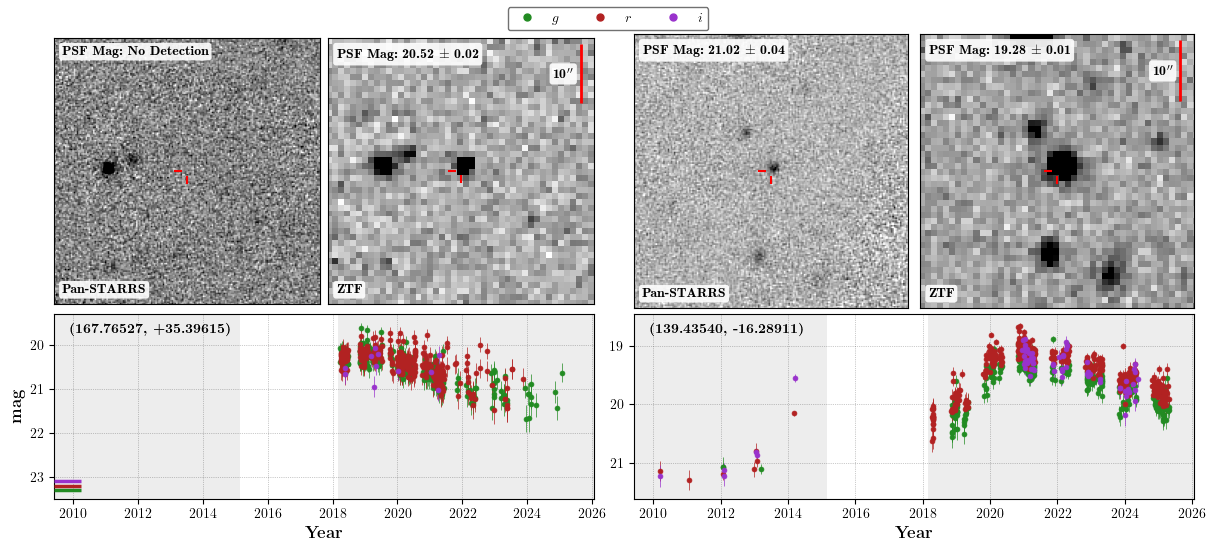

In [53]:
# Just the first row (first two targets) of the figure above.
ncol = 2
fig = plt.figure(figsize=(BLOCK_W * ncol, CUTOUT_H + LC_H + 0.4), constrained_layout=True)
fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, wspace=0.04, hspace=0.04)
blocks = fig.add_gridspec(1, ncol)
for col, src in enumerate(picked[:ncol]):
    block = blocks[0, col].subgridspec(2, 2, height_ratios=[CUTOUT_H, LC_H], wspace=0, hspace=0.02)
    draw_cutout(fig.add_subplot(block[0, 0]), src, 'Pan-STARRS')
    draw_cutout(fig.add_subplot(block[0, 1]), src, 'ZTF')
    ax = fig.add_subplot(block[1, :])
    draw_light_curve(ax, src)
    ax.set_xlabel(r'\textbf{Year}')
    if col == 0:
        ax.set_ylabel(r'\textbf{mag}')

handles = [Line2D([], [], ls='none', marker='o', ms=5, color=LC_COLOR_INFO[b], label=f'${b}$') for b in BANDS]
fig.legend(handles=handles, loc='outside upper center', ncol=len(BANDS), fontsize=10, edgecolor='0.3')

plt.savefig('/Users/adamboesky/Research/long_transients/Figures/lightcurves_cutouts_gemini_2027A_highlight_row1.pdf')
plt.show()